# GDP Predictor — versión corregida

Esta es la versión revisada del notebook original de Colab (`GDP_predictor.ipynb`).
Mantiene la misma idea (Random Forest, LSTM y Prophet sobre el dataset
*Global Economy Indicators*), pero corrige los errores que impedían ejecutarlo
fuera de Colab y, sobre todo, los **errores metodológicos** que hacían que los
resultados parecieran mejores de lo que eran.

| # | Problema en el original | Corrección |
|---|---|---|
| 1 | `from google.colab import drive` rompe fuera de Colab | se importa solo si estamos en Colab |
| 2 | Columnas y países con espacios (`' Country '`) | `str.strip()` al leer |
| 3 | **Fuga de datos (leakage)** en el Random Forest: usa GNI, Total Value Added, consumo, inversión, exportaciones e importaciones **del mismo año**. PBI = C + I + G + X − M, así que el modelo "aprende" una identidad contable, no a predecir | se predice el crecimiento del año siguiente usando solo información pasada (lags) |
| 4 | `train_test_split(shuffle=False)` sobre datos ordenados por país: entrena con Afganistán…Polonia y testea con Portugal…Zimbabue | split **temporal**: train ≤ 2011, valid 2012–2016, test 2017–2021 |
| 5 | `results` no está definido | `results = pd.DataFrame(search.cv_results_)` |
| 6 | `X_train.columns` después de escalar (ya es un array de numpy) | se guardan los nombres de las columnas antes |
| 7 | Métricas de clasificación importadas (`accuracy_score`, `confusion_matrix`) en un problema de regresión | se quitan; se usan MAPE, RMSE y R² |
| 8 | LSTM: `input_shape=(13, 326)` hardcodeado; split de secuencias por posición (de nuevo, por país) | `n_features` calculado; split por año objetivo |
| 9 | LSTM: PBI en dólares escalado con MinMax entre países (EE.UU. y China aplastan al resto) | se modela el crecimiento logarítmico, comparable entre países |
| 10 | `EarlyStopping` definido pero comentado; `y_scaler` ajustado dos veces | se activa early stopping; un solo escalador |
| 11 | Prophet: `freq='Y'` (deprecado, fechas a fin de año) y se **sobrescribe a mano** el primer punto del pronóstico con el último dato real | `freq='YS'`, sin retoques; se trabaja en log |
| 12 | Etiqueta "80% interval" con `interval_width=0.9`; `mcmc_samples=1000` (muy lento) | etiqueta consistente; MAP en vez de MCMC |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # (1)
    from google.colab import drive
    drive.mount("/content/drive")
    CSV = "/content/drive/MyDrive/Colab Notebooks/data/Global Economy Indicators.csv"
else:
    # funciona tanto ejecutado como script como abierto en Jupyter desde notebooks/
    here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
    CSV = next(p / "data" / "raw" / "global_economy_indicators.csv" for p in [here, *here.parents]
               if (p / "data" / "raw" / "global_economy_indicators.csv").exists())

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from scipy.stats import randint

## 1. Carga y limpieza

In [2]:
df = pd.read_csv(CSV)
df.columns = df.columns.str.strip()                         # (2)
df["Country"] = df["Country"].str.strip()
df["Currency"] = df["Currency"].str.strip()

counts = df["Country"].value_counts()
complete = counts[counts == 52].index                     # países con 1970-2021 completo
df = df[df["Country"].isin(complete)].sort_values(["Country", "Year"]).reset_index(drop=True)
df = df[df.groupby("Country")["Gross Domestic Product (GDP)"].transform(lambda s: (s > 0).all())]
print(df.shape, df["Country"].nunique(), "países")

(9308, 26) 179 países


## 2. Random Forest — primero, el error original (para entender la fuga de datos)

Replicamos el planteo original: predecir el PBI de un año con las demás
columnas **del mismo año**. El R² sale casi perfecto… porque varias columnas
son, literalmente, partes del PBI.

In [3]:
GDP = "Gross Domestic Product (GDP)"
leaky = df.drop(columns=["CountryID", "Country", "Currency", GDP]).fillna(0)
train_mask, test_mask = df["Year"] <= 2016, df["Year"] > 2016   # al menos el split ahora es temporal
rf_leaky = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)
rf_leaky.fit(leaky[train_mask], df.loc[train_mask, GDP])
print("R² 'con fuga' en test:", round(r2_score(df.loc[test_mask, GDP], rf_leaky.predict(leaky[test_mask])), 4))
print(pd.Series(rf_leaky.feature_importances_, index=leaky.columns).sort_values(ascending=False).head(5))
# -> Las variables más "importantes" son GNI y Total Value Added: casi el mismo número que el PBI.
#    Para pronosticar el futuro no tenemos esos valores, así que este modelo no sirve para predecir.

R² 'con fuga' en test: 0.9815
Gross National Income(GNI) in USD                             0.558737
Total Value Added                                             0.312162
General government final consumption expenditure              0.033207
Transport, storage and communication (ISIC I)                 0.032570
Wholesale, retail trade, restaurants and hotels (ISIC G-H)    0.025108
dtype: float64


## 3. Random Forest corregido: predecir el crecimiento del año siguiente con lags

- **Target**: crecimiento logarítmico del año siguiente `g(t+1) = log PBI(t+1) − log PBI(t)`.
  Es estacionario y comparable entre países (un 3 % es un 3 % en Uruguay o en EE.UU.).
- **Features**: solo información disponible en `t` (crecimientos pasados, volatilidad,
  nivel, peso de sectores, ciclo mundial).

In [4]:
d = df[["Country", "Year", GDP, "Population",
        "Agriculture, hunting, forestry, fishing (ISIC A-B)", "Mining, Manufacturing, Utilities (ISIC C-E)",
        "Exports of goods and services", "Imports of goods and services", "Gross capital formation"]].copy()
d.columns = ["country", "year", "gdp", "pop", "agri", "ind", "exp", "imp", "inv"]
d["log_gdp"] = np.log(d["gdp"])
d["g"] = d.groupby("country")["log_gdp"].diff()
for k in range(1, 4):
    d[f"g_lag{k}"] = d.groupby("country")["g"].shift(k - 1)          # g_lag1 = crecimiento de t
d["g_mean5"] = d.groupby("country")["g"].transform(lambda s: s.rolling(5).mean())
d["g_std5"] = d.groupby("country")["g"].transform(lambda s: s.rolling(5).std())
d["log_gdp_pc"] = np.log(d["gdp"] / d["pop"])
d["agri_share"] = d["agri"] / d["gdp"]
d["ind_share"] = d["ind"] / d["gdp"]
d["openness"] = (d["exp"] + d["imp"]) / d["gdp"]
d["inv_share"] = d["inv"] / d["gdp"]
d["world_g"] = d.groupby("year")["g"].transform("mean")
d["target"] = d.groupby("country")["g"].shift(-1)                    # crecimiento de t+1
FEATS = ["g_lag1", "g_lag2", "g_lag3", "g_mean5", "g_std5", "log_gdp_pc",
         "agri_share", "ind_share", "openness", "inv_share", "world_g"]
d = d.dropna(subset=FEATS + ["target"])

# split temporal por el año del TARGET (t+1)                         (4)
tr = d[d["year"] + 1 <= 2011]
va = d[(d["year"] + 1 > 2011) & (d["year"] + 1 <= 2016)]
te = d[d["year"] + 1 > 2016]
X_tr, X_va, X_te = tr[FEATS], va[FEATS], te[FEATS]                   # se mantienen como DataFrame (6)
y_tr, y_va, y_te = tr["target"], va["target"], te["target"]
# (los árboles no necesitan escalado: cortan por umbrales, la escala no cambia nada)

In [5]:
param_dist = {
    "n_estimators": randint(200, 600),
    "max_depth": [None, 8, 12, 20],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(2, 15),
    "max_features": ["sqrt", 0.5, 0.8],
}
search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1), param_dist, n_iter=20,
    cv=TimeSeriesSplit(n_splits=3),          # CV que respeta el orden temporal
    scoring="neg_root_mean_squared_error", random_state=42, n_jobs=-1, verbose=0,
)
search.fit(X_tr.sort_index(), y_tr.sort_index())
best_rf = search.best_estimator_
results = pd.DataFrame(search.cv_results_)                           # (5)


def report(name, y_true_g, y_pred_g, base_log):
    """Métricas en crecimiento y en nivel de PBI (USD)."""
    gdp_true = np.exp(base_log + y_true_g)
    gdp_pred = np.exp(base_log + y_pred_g)
    print(f"{name:<22} RMSE crecimiento: {np.sqrt(mean_squared_error(y_true_g, y_pred_g)) * 100:5.2f} pp | "
          f"MAPE PBI: {mean_absolute_percentage_error(gdp_true, gdp_pred) * 100:5.2f} % | "
          f"R² nivel: {r2_score(np.log(gdp_true), np.log(gdp_pred)):.4f}")


print("Mejores hiperparámetros:", search.best_params_)
report("Naive (crec. = 0)", y_te, np.zeros(len(y_te)), te["log_gdp"])
report("Drift (crec. = media5)", y_te, te["g_mean5"], te["log_gdp"])
report("RF validación", y_va, best_rf.predict(X_va), va["log_gdp"])
report("RF test", y_te, best_rf.predict(X_te), te["log_gdp"])
# Siempre comparar contra una línea base: si el modelo no le gana a "el PBI
# sigue igual", no aporta nada por más complejo que sea.
# Ojo con el R² en nivel: da 0,998 hasta para el modelo ingenuo, porque el PBI de
# EE. UU. y el de Tuvalu están a 6 órdenes de magnitud. Por eso el R² original
# "impresionaba": no mide capacidad de pronóstico. MAPE y RMSE de crecimiento sí.

Mejores hiperparámetros: {'max_depth': None, 'max_features': 0.8, 'min_samples_leaf': 7, 'min_samples_split': 3, 'n_estimators': 543}
Naive (crec. = 0)      RMSE crecimiento: 10.52 pp | MAPE PBI:  8.12 % | R² nivel: 0.9983
Drift (crec. = media5) RMSE crecimiento: 10.89 pp | MAPE PBI:  7.82 % | R² nivel: 0.9982
RF validación          RMSE crecimiento: 11.54 pp | MAPE PBI:  8.62 % | R² nivel: 0.9980


RF test                RMSE crecimiento:  9.77 pp | MAPE PBI:  6.99 % | R² nivel: 0.9985


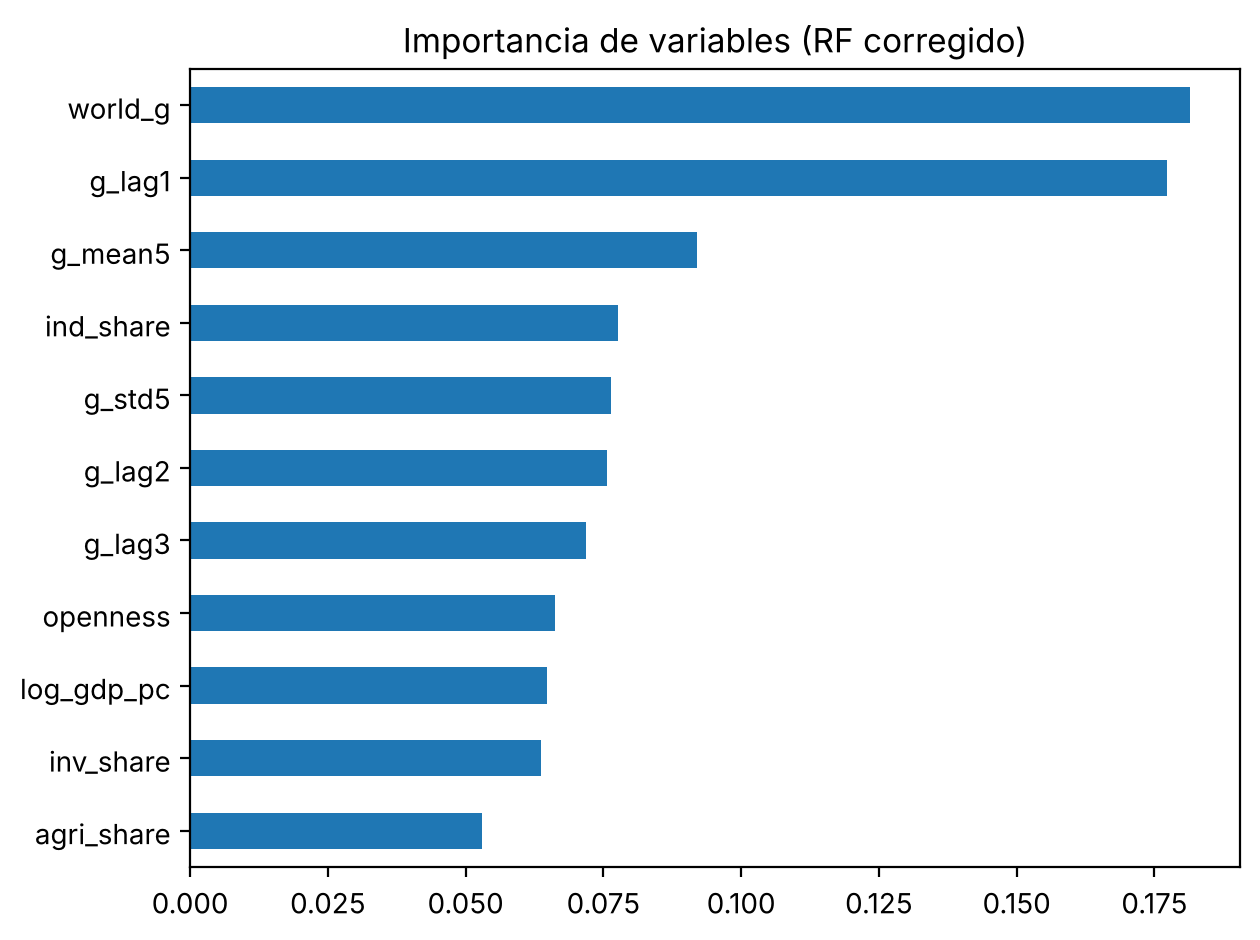

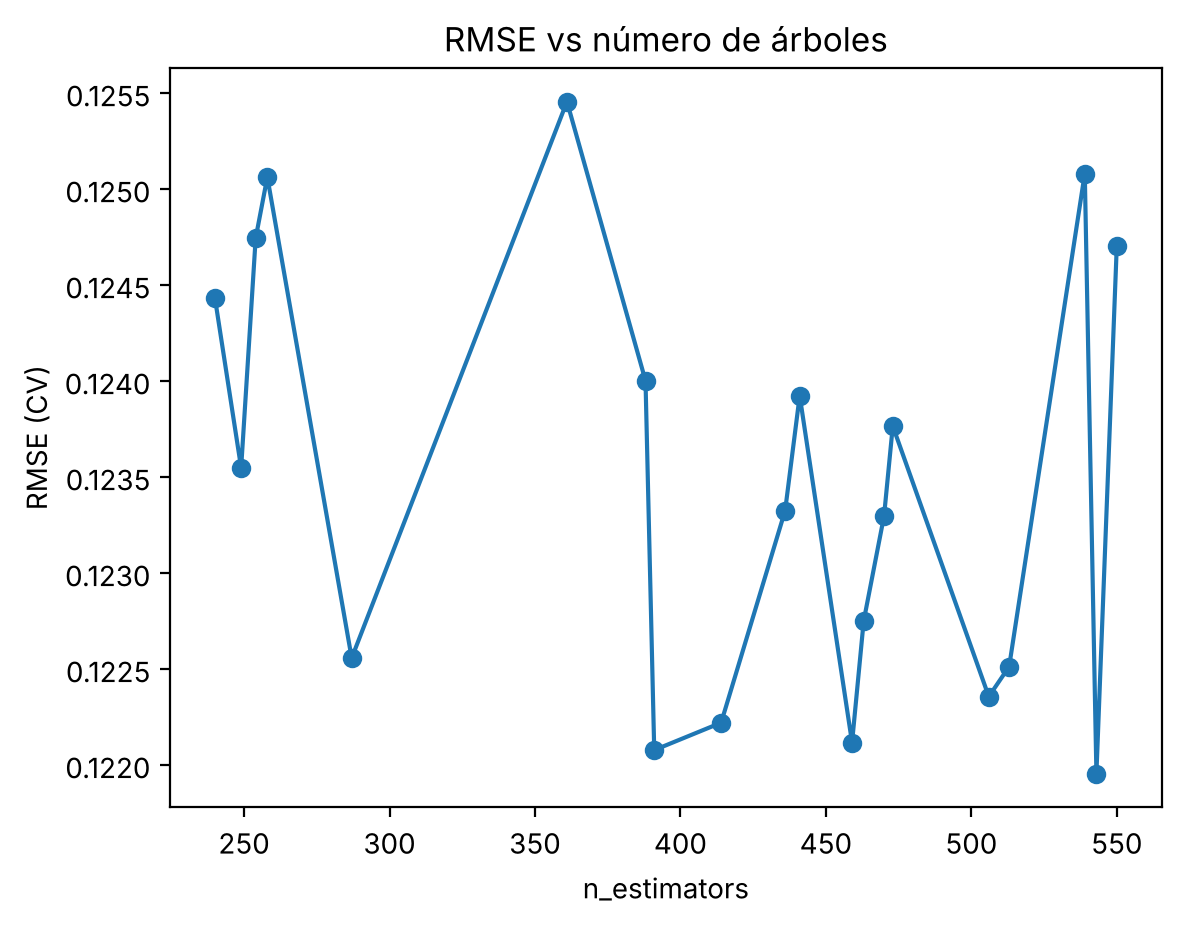

In [6]:
importances = pd.Series(best_rf.feature_importances_, index=FEATS).sort_values()
importances.plot(kind="barh", title="Importancia de variables (RF corregido)")
plt.tight_layout(); plt.show()

scores = results[["param_n_estimators", "mean_test_score"]].dropna().sort_values("param_n_estimators")
plt.plot(scores["param_n_estimators"], -scores["mean_test_score"], "o-")
plt.xlabel("n_estimators"); plt.ylabel("RMSE (CV)"); plt.title("RMSE vs número de árboles"); plt.show()

## 4. LSTM corregida

Secuencias de los últimos 13 crecimientos de cada país → crecimiento del año siguiente.
Split por el año del target, escalado ajustado solo con train, early stopping activo.

I0000 00:00:1794979257.378813   10021 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794979257.427778   10021 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794979258.872087   10021 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


LSTM test              RMSE crecimiento: 12.39 pp | MAPE PBI:  9.30 % | R² nivel: 0.9976


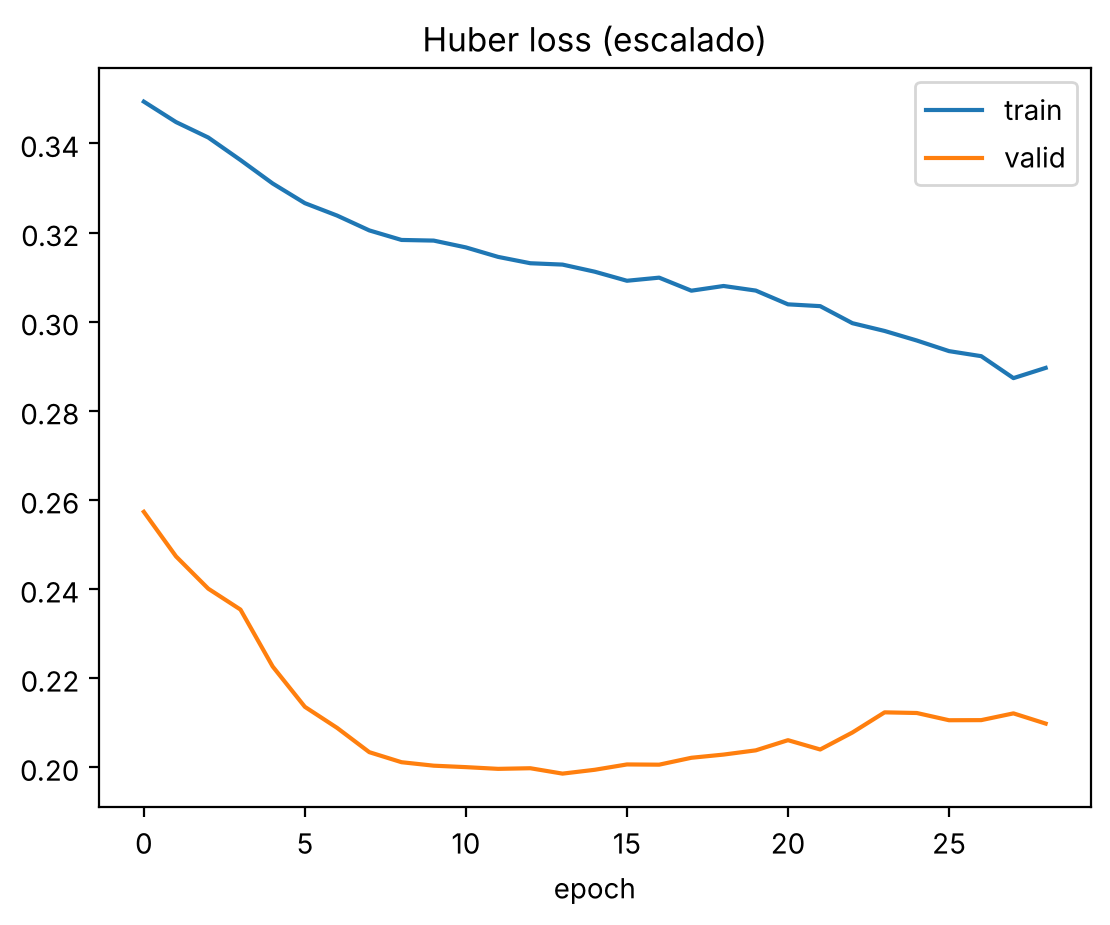

In [7]:
from tensorflow import keras
keras.utils.set_random_seed(42)

WINDOW = 13
SEQ_FEATS = ["g", "world_g"]
full = df[["Country", "Year", GDP]].copy()
full.columns = ["country", "year", "gdp"]
full["log_gdp"] = np.log(full["gdp"])
full["g"] = full.groupby("country")["log_gdp"].diff()
full["world_g"] = full.groupby("year")["g"].transform("mean")

Xs, ys, years, bases = [], [], [], []
for c, g in full.groupby("country"):
    g = g.dropna(subset=["g"]).reset_index(drop=True)
    for i in range(len(g) - WINDOW):
        Xs.append(g.loc[i:i + WINDOW - 1, SEQ_FEATS].values)
        ys.append(g.loc[i + WINDOW, "g"])
        years.append(g.loc[i + WINDOW, "year"])
        bases.append(g.loc[i + WINDOW - 1, "log_gdp"])
X, y, years, bases = np.array(Xs, np.float32), np.array(ys, np.float32), np.array(years), np.array(bases)

tr, va, te = years <= 2011, (years > 2011) & (years <= 2016), years > 2016   # (8)
n_features = X.shape[2]
mu, sd = X[tr].reshape(-1, n_features).mean(0), X[tr].reshape(-1, n_features).std(0)
ymu, ysd = y[tr].mean(), y[tr].std()                                         # (9)(10) un solo escalador
Xn, yn = (X - mu) / sd, (y - ymu) / ysd

model = keras.Sequential([
    keras.Input((WINDOW, n_features)),
    keras.layers.LSTM(32, return_sequences=True), keras.layers.Dropout(0.2),
    keras.layers.LSTM(16), keras.layers.Dropout(0.2),
    keras.layers.Dense(1),
])
model.compile(optimizer=keras.optimizers.Adam(5e-4), loss=keras.losses.Huber(1.0), metrics=["mae"])
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
history = model.fit(Xn[tr], yn[tr], validation_data=(Xn[va], yn[va]), epochs=200, batch_size=64,
                    callbacks=[early_stop], verbose=0)                       # (10)

pred = model.predict(Xn[te], verbose=0).ravel() * ysd + ymu
report("LSTM test", y[te], pred, bases[te])

plt.plot(history.history["loss"], label="train"); plt.plot(history.history["val_loss"], label="valid")
plt.legend(); plt.title("Huber loss (escalado)"); plt.xlabel("epoch"); plt.show()

## 5. Prophet corregido

Importing plotly failed. Interactive plots will not work.


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
05:21:34 - cmdstanpy - INFO - Chain [1] start processing


05:21:34 - cmdstanpy - INFO - Chain [1] done processing


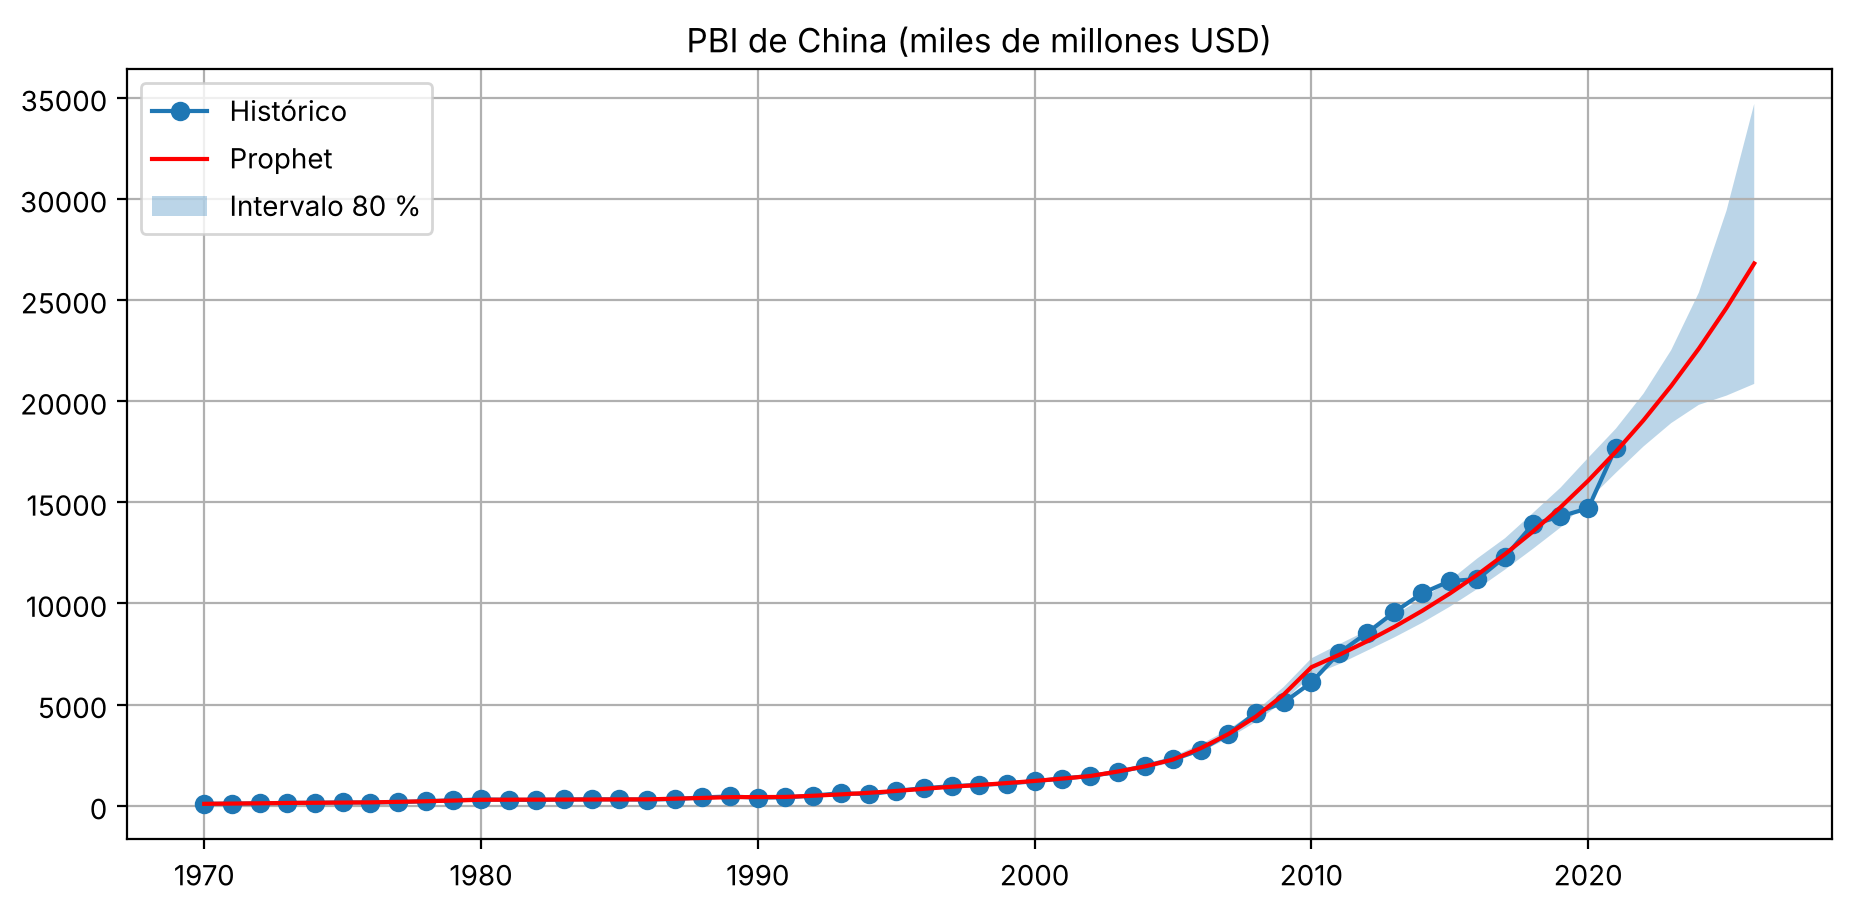

05:21:34 - cmdstanpy - INFO - Chain [1] start processing


05:21:34 - cmdstanpy - INFO - Chain [1] done processing


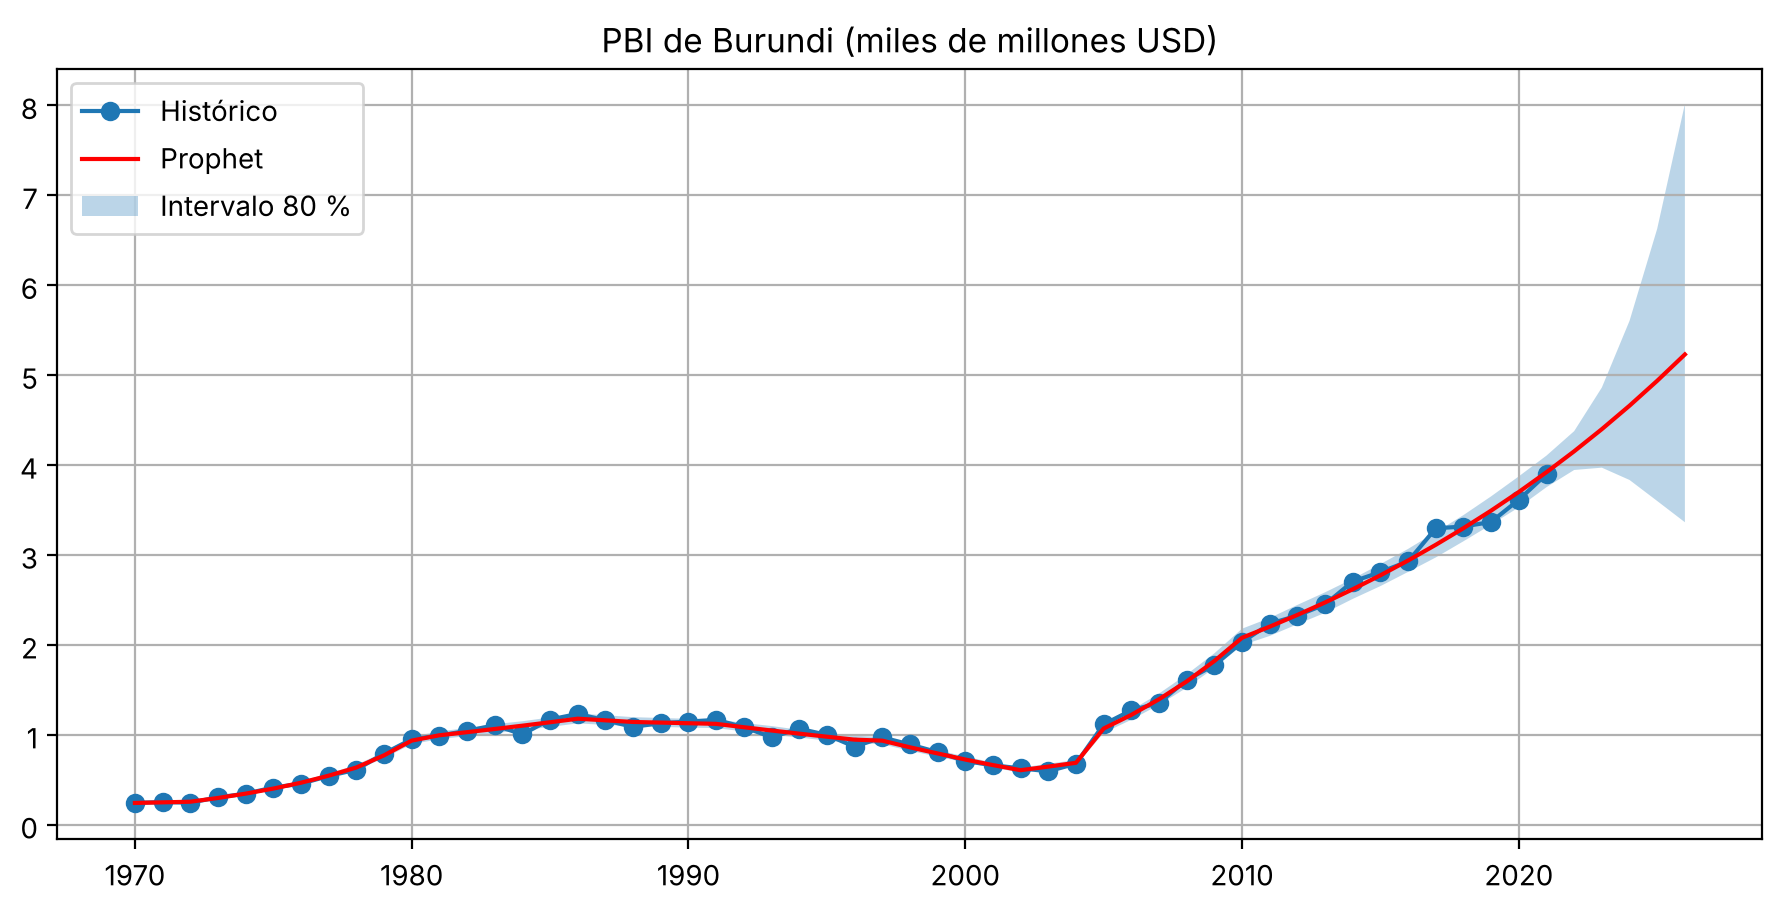

05:21:34 - cmdstanpy - INFO - Chain [1] start processing


05:21:35 - cmdstanpy - INFO - Chain [1] done processing


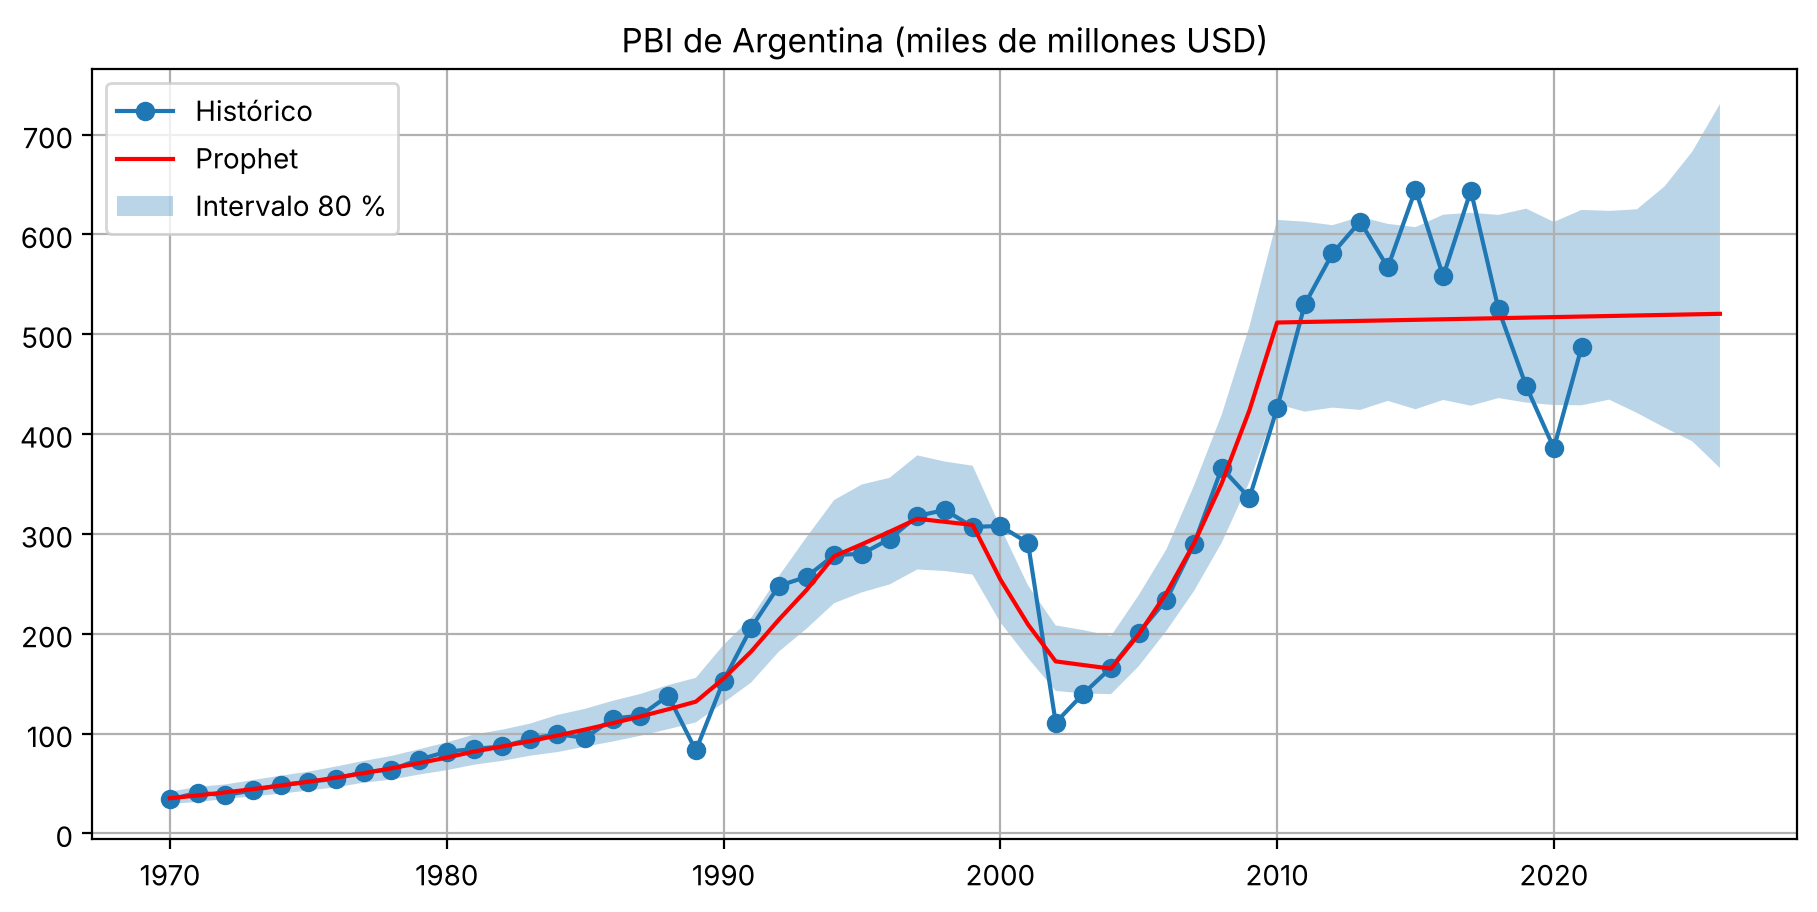

In [8]:
from prophet import Prophet


def prophet_forecast(country, years_future=5, interval=0.8):
    g = full[full["country"] == country]
    dfp = pd.DataFrame({"ds": pd.to_datetime(g["year"].astype(str) + "-01-01"), "y": g["log_gdp"]})
    m = Prophet(interval_width=interval, yearly_seasonality=False, weekly_seasonality=False,
                daily_seasonality=False, changepoint_prior_scale=0.1)
    m.fit(dfp)
    future = m.make_future_dataframe(periods=years_future, freq="YS")      # (11)
    fc = m.predict(future)
    for col in ["yhat", "yhat_lower", "yhat_upper"]:
        fc[col] = np.exp(fc[col]) / 1e9                                    # de log a miles de millones
    return g, fc


for country in ["China", "Burundi", "Argentina"]:
    g, fc = prophet_forecast(country)
    plt.figure(figsize=(11, 5))
    plt.plot(g["year"], g["gdp"] / 1e9, "o-", label="Histórico")
    plt.plot(fc["ds"].dt.year, fc["yhat"], color="red", label="Prophet")
    plt.fill_between(fc["ds"].dt.year, fc["yhat_lower"], fc["yhat_upper"], alpha=0.3,
                     label="Intervalo 80 %")                               # (12)
    plt.title(f"PBI de {country} (miles de millones USD)"); plt.legend(); plt.grid(True); plt.show()

## Conclusión

Con la fuga de datos corregida, el R² "casi perfecto" desaparece y aparece la
pregunta correcta: **¿el modelo le gana a una línea base simple?** El proyecto
completo (`pipeline/`) compara 11 modelos en 179 países con varios orígenes de
backtest y una prueba real contra datos 2022–2023 del Banco Mundial.